--- Phase 1: Ridge CV Results ---
Degree   | Best Alpha   | CV MSE    
--------------------------------------
1        | 30.0         | 9.1357
2        | 10.0         | 3.2591
3        | 3.0          | 1.1110
4        | 10.0         | 0.8323
5        | 10.0         | 0.6335
6        | 30.0         | 0.7204
7        | 30.0         | 0.8464


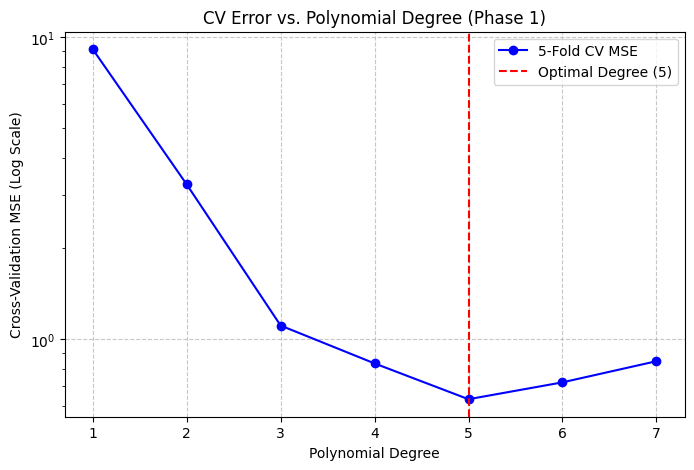

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

# Load training data
train_var1 = pd.read_csv('BT2024168_train_var1.csv')
X1 = train_var1[['x1', 'x2', 'x3', 'x4', 'x5', 'x6']]
y1 = train_var1['y']

# Configure 5-fold cross-validation and hyperparameter grid
kf = KFold(n_splits=5, shuffle=True, random_state=42)
alphas = [0.1, 1.0, 3.0, 10.0, 30.0]
degrees = range(1, 8)
cv_mses = []

print("--- Phase 1: Ridge CV Results ---")
print(f"{'Degree':<8} | {'Best Alpha':<12} | {'CV MSE':<10}")
print("-" * 38)

# Evaluate degrees 1 through 7
for degree in degrees:
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge())
    ])

    grid = GridSearchCV(pipe, {'ridge__alpha': alphas}, cv=kf, scoring='neg_mean_squared_error')
    grid.fit(X1, y1)

    best_alpha = grid.best_params_['ridge__alpha']
    cv_mse = -grid.best_score_
    cv_mses.append(cv_mse)

    print(f"{degree:<8} | {best_alpha:<12} | {cv_mse:.4f}")

# Plot Cross-Validation MSE vs Degree
plt.figure(figsize=(8, 5))
plt.plot(degrees, cv_mses, marker='o', linestyle='-', color='b', label='5-Fold CV MSE')
plt.axvline(x=5, color='r', linestyle='--', label='Optimal Degree (5)')
plt.title('CV Error vs. Polynomial Degree (Phase 1)')
plt.xlabel('Polynomial Degree')
plt.ylabel('Cross-Validation MSE (Log Scale)')
plt.yscale('log')
plt.xticks(degrees)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

--- Phase 2: Ridge CV Results ---
Degree   | Best Alpha   | CV MSE    
--------------------------------------
1        | 10.0         | 34.2180
2        | 10.0         | 21.6209
3        | 0.01         | 11.0152
4        | 0.01         | 3.6396
5        | 0.1          | 1.3563
6        | 0.1          | 0.5596
7        | 0.01         | 0.3307
8        | 0.01         | 0.2684
9        | 0.1          | 0.2683
10       | 1.0          | 0.2594
11       | 1.0          | 0.2612
12       | 1.0          | 0.2656
13       | 1.0          | 0.2716


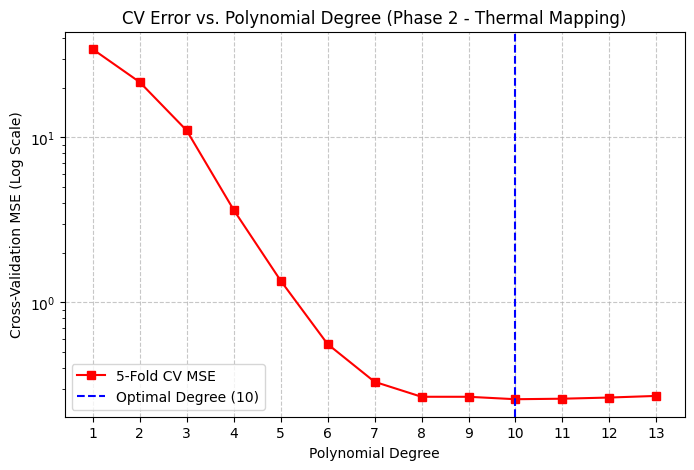

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

# Load Phase 2 training data
train_var2 = pd.read_csv('BT2024168_train_var2.csv')
X2 = train_var2[['x1', 'x2', 'x3']]
y2 = train_var2['y']

# Configure 5-fold cross-validation and hyperparameter grid
kf = KFold(n_splits=5, shuffle=True, random_state=42)
alphas2 = [0.01, 0.1, 1.0, 10.0]
degrees2 = range(1, 14) # Checking up to 13 to see the plateau
cv_mses2 = []

print("--- Phase 2: Ridge CV Results ---")
print(f"{'Degree':<8} | {'Best Alpha':<12} | {'CV MSE':<10}")
print("-" * 38)

# Evaluate degrees 1 through 13
for degree in degrees2:
    pipe2 = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge(max_iter=10000))
    ])

    grid2 = GridSearchCV(pipe2, {'ridge__alpha': alphas2}, cv=kf, scoring='neg_mean_squared_error')
    grid2.fit(X2, y2)

    best_alpha2 = grid2.best_params_['ridge__alpha']
    cv_mse2 = -grid2.best_score_
    cv_mses2.append(cv_mse2)

    print(f"{degree:<8} | {best_alpha2:<12} | {cv_mse2:.4f}")

# Plot Cross-Validation MSE vs Degree
plt.figure(figsize=(8, 5))
plt.plot(degrees2, cv_mses2, marker='s', linestyle='-', color='r', label='5-Fold CV MSE')
plt.axvline(x=10, color='b', linestyle='--', label='Optimal Degree (10)')
plt.title('CV Error vs. Polynomial Degree (Phase 2 - Thermal Mapping)')
plt.xlabel('Polynomial Degree')
plt.ylabel('Cross-Validation MSE (Log Scale)')
plt.yscale('log')
plt.xticks(degrees2)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [4]:
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

# ==========================================
# Phase 1: Final Predictions (var1)
# ==========================================
train_var1 = pd.read_csv('BT2024168_train_var1.csv')
test_var1 = pd.read_csv('BT2024168_test_var1.csv')

X1_train = train_var1[['x1', 'x2', 'x3', 'x4', 'x5', 'x6']]
y1_train = train_var1['y']
X1_test = test_var1[['x1', 'x2', 'x3', 'x4', 'x5', 'x6']]

# Optimal settings from Phase 1 CV: Degree 5, Alpha 10.0
final_pipe1 = Pipeline([
    ('poly', PolynomialFeatures(degree=5, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=10.0))
])

# Train on full training data and predict on test data
final_pipe1.fit(X1_train, y1_train)
pred1 = final_pipe1.predict(X1_test)

# Save Phase 1 predictions
pd.DataFrame({'y': pred1}).to_csv('BT2024168_pred_var1.csv', index=False)
print("Phase 1 predictions saved to BT2024168_pred_var1.csv")

# ==========================================
# Phase 2: Final Predictions (var2)
# ==========================================
train_var2 = pd.read_csv('BT2024168_train_var2.csv')
test_var2 = pd.read_csv('BT2024168_test_var2.csv')

X2_train = train_var2[['x1', 'x2', 'x3']]
y2_train = train_var2['y']
X2_test = test_var2[['x1', 'x2', 'x3']]

# Optimal settings from Phase 2 CV: Degree 10, Alpha 1.0
final_pipe2 = Pipeline([
    ('poly', PolynomialFeatures(degree=10, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0, max_iter=10000))
])

# Train on full training data and predict on test data
final_pipe2.fit(X2_train, y2_train)
pred2 = final_pipe2.predict(X2_test)

# Save Phase 2 predictions
pd.DataFrame({'y': pred2}).to_csv('BT2024168_pred_var2.csv', index=False)
print("Phase 2 predictions saved to BT2024168_pred_var2.csv")

Phase 1 predictions saved to BT2024168_pred_var1.csv
Phase 2 predictions saved to BT2024168_pred_var2.csv
